# Training an RLM on HotpotQA multi-hop questions

A language model’s **context window** limits the tokens it can process in one call. The evidence for an answer may be scattered across documents that together exceed that limit. A **recursive language model (RLM)** keeps the input in an external environment, such as a Python read–eval–print loop (REPL). The root runs code to inspect selected passages and can send a focused question and a slice of the input to a child model. Each model call still has its own context limit. Alex L. Zhang and Omar Khattab introduced the idea in 2025 and later developed it in a paper with Tim Kraska. [Original introduction](https://alexzhang13.github.io/blog/2025/rlm/) · [Recursive Language Models paper](https://arxiv.org/abs/2512.24601)

In **HotpotQA**, a question might require finding a book’s author in one Wikipedia article and looking up that author’s birthplace in another. The root can use the REPL to locate the articles, delegate the lookups, and combine the evidence. [HotpotQA paper](https://aclanthology.org/D18-1259/)

This notebook uses a **hierarchical multi-agent system**. OpenEnv runs the root’s Python REPL, which stores the candidate articles as a variable. The root delegates evidence checks to child agents with their own REPLs, then uses their replies to submit the final answer. GRPO updates a LoRA adapter on the root, and the children use frozen Qwen3.5-4B weights. [OpenEnv REPL](https://github.com/openenv/OpenEnv/tree/main/envs/repl_env)

We start from alphaXiv’s **Qwen3.5-4B SFT checkpoint** for evidence selection across scientific documents. It gives the root practice using a REPL and delegating before it starts learning from HotpotQA answer rewards. Daniel Kim and Rehaan Ahmad describe this warm start in their alphaXiv blog post. [SFT checkpoint](https://huggingface.co/alphaXiv/evidence-multi-rlm-sft-4b) · [Reinforcing Recursive Language Models](https://www.alphaxiv.org/blog/reinforcement-learning-for-rlms)

Select a **T4 GPU** in Colab. The full run uses 20 training and 20 held-out questions. The saved run took about 92 minutes for training, with evaluation afterward. Use the quick run below to try the workflow on one training and one held-out question.

## An RLM with a Python REPL

![Figure 1. The root model inspects context in a REPL, delegates subqueries, and uses child responses to answer the original question.](https://alexzhang13.github.io/assets/img/rlm/teaser.png)

*Figure 1 by Alex L. Zhang and Omar Khattab, from [Recursive Language Models](https://alexzhang13.github.io/blog/2025/rlm/).*

## Choose a run and optionally sign in

Set `QUICK_RUN = True` for one training question and one held-out question. Both modes sample four trajectories per training question.

Leave `HUB_MODEL_ID` empty to save the adapter locally. To upload it, set the destination to `your-username/your-model` and enter a token with write access at the hidden prompt.

In [1]:
import json
from getpass import getpass
from urllib.error import HTTPError
from urllib.request import Request, urlopen


QUICK_RUN = False
HUB_MODEL_ID = ""


def check_hub_token():
    token = getpass("Hugging Face write token: ").strip()
    if not token:
        raise ValueError("Enter a Hugging Face token with write access to the model repository.")
    request = Request("https://huggingface.co/api/whoami-v2", headers={"Authorization": f"Bearer {token}"})
    try:
        with urlopen(request, timeout=30) as response:
            account = json.load(response)
    except HTTPError as error:
        if error.code == 401:
            raise ValueError("Hugging Face rejected the token. Check it and rerun this cell.") from None
        raise
    print(f"Signed in to Hugging Face as {account['name']}")
    return token


hub_token = check_hub_token() if HUB_MODEL_ID else None

Hugging Face write token: ··········
Signed in to Hugging Face as jucamohedano


## 1. Set up the T4 runtime

Fetch the pinned OpenEnv revision once. The cell installs OpenEnv from that checkout and makes its REPL example importable.

In [2]:
import os
import subprocess
import sys
from pathlib import Path

OPENENV_REPO = "https://github.com/openenv/OpenEnv.git"
OPENENV_REVISION = "1ee1751a7efbc246848bb37a4be6c9f8a26a8e7e"
TRL_REVISION = "99bbdfec75ad1a57bb2df9c72278b391508eda5f"

source = Path("/content/openenv-repl-source")
source.mkdir(exist_ok=True)
subprocess.run(["git", "init", "--quiet"], cwd=source, check=True)
subprocess.run(["git", "fetch", "--quiet", "--depth=1", OPENENV_REPO, OPENENV_REVISION], cwd=source, check=True)
subprocess.run(["git", "checkout", "--quiet", "--detach", OPENENV_REVISION], cwd=source, check=True)

# Use the CUDA build of PyTorch that comes with the Colab runtime.
pip = [sys.executable, "-m", "pip"]
subprocess.run(pip + ["uninstall", "-y", "torchao"], check=True)
subprocess.run(
    pip + [
        "install", "--quiet",
        f"trl[peft] @ git+https://github.com/huggingface/trl.git@{TRL_REVISION}",
        str(source),
        "transformers==5.23.0",
        "datasets==5.0.0",
        "pyarrow>=21,<24",
        "bitsandbytes>=0.45.2",
        "peft==0.21.2",
        "smolagents==1.26.0",
        "trackio==0.45.1",
    ],
    check=True,
)

env_path = str(source / "envs")
if env_path not in sys.path:
    sys.path.insert(0, env_path)
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ["OPENENV_GRPO_ARCHIVE_CHECKPOINT"] = "1"

### Configure the run

This cell selects the root and child checkpoints, sets the question counts from the selected run mode, and prints the GPU and output directory.

In [3]:
import gc
import json
import math
import os
import shutil
import re
import string
import sys
from datetime import UTC, datetime
from functools import cache
from pathlib import Path

loaded_sympy = sys.modules.get("sympy")
if loaded_sympy is not None and not hasattr(loaded_sympy, "logic"):
    raise RuntimeError(
        "The current Colab session has an incomplete SymPy import. "
        "Choose Runtime → Restart session, then rerun the notebook from sign-in."
    )

import torch
from datasets import Dataset, load_dataset
from peft import LoraConfig, PeftModel, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, TrainerCallback

# Set the log location before importing Trackio or TRL.
# Set this to an existing run directory to resume from its latest complete checkpoint.
RUN_DIRECTORY = os.environ.get("OPENENV_GRPO_RUN_DIR")
GRPO_DIR = (
    Path(RUN_DIRECTORY)
    if RUN_DIRECTORY
    else Path("/content/openenv-hotpotqa") / datetime.now(UTC).strftime("%Y%m%dT%H%M%SZ")
)
GRPO_DIR.mkdir(parents=True, exist_ok=True)
os.environ["TRACKIO_DIR"] = str(GRPO_DIR / "trackio")

import trackio
from trl import GRPOConfig, GRPOTrainer


BASE_MODEL = "Qwen/Qwen3.5-4B"
BASE_REVISION = "851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a"
ROOT_MODEL = "alphaXiv/evidence-multi-rlm-sft-4b"
ROOT_REVISION = "a4cc3856d4707d9f935f8ab3a6e6c66e3a25de78"
HOTPOT_REVISION = "1908d6afbbead072334abe2965f91bd2709910ab"
TRAIN_QUESTIONS = 1 if QUICK_RUN else 20
HELDOUT_QUESTIONS = 1 if QUICK_RUN else 20
ROLLOUTS_PER_QUESTION = 4
TRAIN_SEED = 47
PROJECT = "openenv-repl-hotpotqa"
CHECKPOINT_DIR = GRPO_DIR / "checkpoints"

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime before running the pilot.")

gpu = torch.cuda.get_device_properties(0)
print(f"{gpu.name}, {gpu.total_memory / 2**30:.1f} GiB VRAM")
print(f"Root checkpoint: {ROOT_MODEL}")
print(f"Run directory: {GRPO_DIR}")


def load_model(model_id, revision):
    return AutoModelForCausalLM.from_pretrained(
        model_id,
        revision=revision,
        dtype=torch.float16,
        device_map={"": 0},
        attn_implementation="sdpa",
        quantization_config=BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.float16,
        ),
    )


@cache
def frozen_child():
    return load_model(BASE_MODEL, BASE_REVISION).eval()


def write_json(path, contents):
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(contents, indent=2) + "\n")
    temporary.replace(path)

Tesla T4, 14.6 GiB VRAM
Root checkpoint: alphaXiv/evidence-multi-rlm-sft-4b
Run directory: /content/openenv-hotpotqa/20261121T123512Z


## 2. Load HotpotQA

The distractor setting gives us a question and candidate Wikipedia articles. The REPL receives a JSON string keyed by article title. The gold answer is kept separately for scoring. Both modes use a fixed question order. The full run uses 20 training questions and evaluates the ten pilot validation questions plus the first ten other rows of the pinned validation split. The quick run takes the first question from each of those selections.

In [4]:
PILOT_TRAIN_IDS = [
    "5a7bb354554299042af8f79b",
    "5ab63c4a5542995eadeeff8c",
    "5a879b5d5542993e715abfc2",
    "5ae626865542992663a4f26d",
    "5ac4988c5542996feb3fe900",
    "5adfdcca55429925eb1afacf",
    "5ae27edc5542992decbdcd2d",
    "5abb121b5542996cc5e49f8b",
    "5a7a5f9a55429941d65f25eb",
    "5ae345d65542992e3233c357",
    "5abaf3385542996cc5e49f2f",
    "5ac4e415554299076e296e33",
]
EXTRA_TRAIN_IDS = [
    "5abc53ed5542996583600443",
    "5a8492aa5542990548d0b2d1",
    "5a81fab9554299676cceb1b1",
    "5a819d2c5542990a1d231e1f",
    "5adca6c05542994d58a2f696",
    "5a8664285542991e77181634",
    "5ab52fd1554299637185c4f7",
    "5ae1394955429901ffe4ae0a"
]

HELDOUT_IDS = [
    "5a83a532554299334474606f",
    "5a88dcf9554299206df2b383",
    "5ac2bbd0554299218029db09",
    "5a7ddc5a5542995f4f4022da",
    "5a7a1cd85542990783324e65",
    "5ae4c49a5542995dadf24400",
    "5abd2eab5542992ac4f38210",
    "5a7b46e55542995eb53be8e5",
    "5a8eea4a5542990e94052bb7",
    "5ab9374b554299131ca422c6",
]


def load_questions(split, ids, count):
    stream = load_dataset("hotpotqa/hotpot_qa", "distractor", revision=HOTPOT_REVISION, split=split, streaming=True)
    ids = ids[:count]
    wanted = set(ids)
    matches, extra = {}, []
    for row in stream:
        question_id = row["id"]
        if question_id in wanted:
            matches[question_id] = row
        elif len(extra) < count - len(ids):
            extra.append(row)
        if len(matches) == len(ids) and len(matches) + len(extra) == count:
            return [matches[question_id] for question_id in ids] + extra
    raise ValueError(f"Could not select {count} questions from {split}.")


# Preserve the pilot's seeded TRL order so a saved checkpoint can be continued.
pilot_order = torch.randperm(len(PILOT_TRAIN_IDS), generator=torch.Generator().manual_seed(TRAIN_SEED)).tolist()
candidate_train_ids = [PILOT_TRAIN_IDS[i] for i in pilot_order] + EXTRA_TRAIN_IDS
rows = load_questions("train", candidate_train_ids, TRAIN_QUESTIONS)
hotpot_by_id = {row["id"]: row for row in rows}
train_ids = list(hotpot_by_id)
grpo_dataset = Dataset.from_dict({"prompt": train_ids, "answer": [row["answer"] for row in rows]})
grpo_tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, revision=BASE_REVISION)
root_tokenizer = AutoTokenizer.from_pretrained(ROOT_MODEL, revision=ROOT_REVISION)
if grpo_tokenizer.get_vocab() != root_tokenizer.get_vocab():
    raise ValueError("The root and child checkpoints must share token IDs.")
write_json(GRPO_DIR / "train-question-ids.json", train_ids)
example = rows[0]
print(f"Loaded {len(rows)} training questions")
print(f"Question: {example['question']}")
print("First three candidate articles:", ", ".join(example["context"]["title"][:3]))


def normalize_answer(text):
    text = text.lower().translate(str.maketrans("", "", string.punctuation))
    return " ".join(re.sub(r"\b(a|an|the)\b", " ", text).split())


def exact_match_reward(answer, submitted_answer, child_calls=None, log_metric=None, **kwargs):
    if log_metric is not None:
        log_metric(
            "non_empty_submission_rate", sum(bool((value or "").strip()) for value in submitted_answer) / len(answer)
        )
        log_metric("mean_child_calls", sum(child_calls) / len(answer))
    return [
        float(submitted is not None and normalize_answer(submitted) == normalize_answer(expected))
        for expected, submitted in zip(answer, submitted_answer, strict=True)
    ]

Loaded 20 training questions
Question: What nominations has the author of the Eugene Trilogy received more of (combined) than any other writer?
First three candidate articles: Broadway Bound, Brighton Beach Memoirs (film), Neil Simon


## 3. Connect TRL to the REPL

A rollout alternates between model generation and Python execution. Here is a captured rollout for the first training question, *What nominations has the author of the Eugene Trilogy received more of (combined) than any other writer?*

1. **Read the context.** The root converts the REPL's JSON context into a dictionary of article titles and text.

   ```python
   import json
   documents = json.loads(context)
   ```

2. **Delegate an evidence check.** The root selects the Neil Simon article and gives it to a child REPL together with a question.

   ```python
   replies = rlm_query_batched([
       "What nominations has the author of the Eugene Trilogy received more of (combined) "
       "than any other writer? Return the specific nominations mentioned."
       "\nArticle:\n" + documents["Neil Simon"],
   ])
   print(replies)
   ```

3. **Return evidence.** The child first runs `print(context)` to read the delegated question and article. On its next turn it runs `FINAL("Oscar and Tony nominations")`. The root's REPL receives `['Oscar and Tony nominations']` as an observation.

4. **Submit and score the answer.** The root submits the short answer. It receives reward **1** because the normalized submission matches the gold answer.

   ```python
   answer["content"] = "Oscar and Tony nominations"
   answer["ready"] = True
   ```

The four rollouts in that group earned `[1, 0, 0, 0]`. GRPO assigns a higher relative advantage to the successful rollout. A group whose rewards are all equal has zero relative advantage. The custom rollout passes the root's generated token IDs and log probabilities to TRL. The observation mask excludes REPL feedback, including child replies, from the loss.

In [5]:
import time

from repl_env.recursive_backends import BackendLimits, LocalChildRLMBackend
from repl_env.runner import LocalRLMRunner
from transformers import GenerationConfig

from trl.models.utils import unwrap_model_for_generation


MAX_DEPTH = 2  # The root can spawn one level of child REPLs.
PARENT_TURNS = 6
CHILD_TURNS = 3
ROOT_SYSTEM_PROMPT = (
    "You coordinate evidence checks across Wikipedia articles to answer a short HotpotQA question.\n"
    "The REPL holds context as a JSON string mapping titles to article text. Use one fenced repl block per reply.\n"
    "Use up to six turns for this workflow. Reserve your last turn for submission:\n"
    "1. Inspect article titles and short excerpts. Identify the likely bridge entity or the articles that bear on each part.\n"
    "2. Dispatch focused evidence checks. Each child needs the actual article text and a question about that article.\n"
    "   Use rlm_query_batched for two independent checks, one child per article. If the second check depends on the first,\n"
    "   dispatch just the first check and use its result to identify the next article. Make at least one recursive check.\n"
    "3. Read the child reply, then use a brief REPL lookup if you need to verify the link between the articles.\n"
    "4. Submit only the exact short answer by setting answer['content'] and answer['ready'] = True.\n"
    "\n"
    "Example: for a question about the nationality of the creator of a fictional artifact, the first article can\n"
    "identify the creator while a candidate biography supplies the nationality. If you have located both titles,\n"
    "give one subquestion and its article to each child. Compare the creator name with the biography title before answering.\n"
    "\n"
    "```repl\n"
    "# artifact_title and biography_title are titles selected from the article dictionary.\n"
    "replies = rlm_query_batched([\n"
    '    "Who created the artifact? Return the sentence that names the creator.\\nArticle:\\n" + documents[artifact_title],\n'
    '    "What nationality is the person in this biography? Return the sentence that states it.\\nArticle:\\n"\n'
    "    + documents[biography_title],\n"
    "])\n"
    "print(replies)\n"
    "```\n"
    "\n"
    "Start with import json and documents = json.loads(context). Keep the existing answer dictionary for submitting."
)

CHILD_SYSTEM_PROMPT = (
    "You are a Wikipedia evidence worker. Your REPL context string contains one delegated question and its article.\n"
    "Use one fenced repl block per reply. Inspect the supplied context, then return one short verbatim sentence\n"
    "or phrase that answers the delegated question. You have up to three turns. If the article does not\n"
    "contain the evidence, return an empty string. Submit with FINAL inside the REPL block.\n"
    "\n"
    "First turn:\n"
    "```repl\n"
    "print(context)\n"
    "```\n"
    "Second turn, after reading the output (replace the example sentence with the relevant excerpt):\n"
    "```repl\n"
    'FINAL("The article states the relevant fact in this sentence.")\n'
    "```"
)

TOKENS_PER_TURN = 192
ROLLOUT_TOKEN_LIMIT = 4096
ROLLOUT_TIME_LIMIT = 300  # Seconds across the root and children.


def compact_repl_errors(observation):
    # Keep the first error line and the rest of the REPL conversation.
    return re.sub(
        r"(?ms)(^ERROR: [^\n]*).*?(?=\n\n(?:Code executed:|The history before)|\Z)",
        lambda match: match[1][:300],
        observation,
    )


def chat_ids(messages):
    return grpo_tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, enable_thinking=False, return_dict=False
    )


def sample_turn(model, ids, max_tokens, time_budget, temperature=None):
    sampled = temperature is not None
    generation = GenerationConfig(
        max_new_tokens=max_tokens,
        max_time=time_budget,
        do_sample=sampled,
        temperature=temperature or 1.0,
        top_k=0,
        eos_token_id=grpo_tokenizer.eos_token_id,
        pad_token_id=grpo_tokenizer.pad_token_id,
        use_cache=True,
        return_dict_in_generate=True,
        output_scores=sampled,
    )
    tokens = torch.tensor([ids], device=model.device)
    output = model.generate(tokens, attention_mask=torch.ones_like(tokens), generation_config=generation)
    generated = output.sequences[0, len(ids) :].tolist()
    logps = []
    if sampled:
        logps = torch.stack(
            [
                score[0].log_softmax(-1, dtype=torch.float32)[token]
                for score, token in zip(output.scores, generated, strict=True)
            ]
        ).tolist()
    return generated, logps


def article_context(row):
    articles = row["context"]
    return json.dumps(
        {title: "".join(sentences) for title, sentences in zip(articles["title"], articles["sentences"], strict=True)},
        ensure_ascii=False,
    )


class RolloutTimeLimit(TimeoutError):
    pass


def run_hotpot_rollout(row, model, temperature):
    started = time.monotonic()

    def time_remaining():
        seconds = ROLLOUT_TIME_LIMIT - (time.monotonic() - started)
        if seconds <= 0:
            raise RolloutTimeLimit("The rollout time budget has expired.")
        return seconds

    context = article_context(row)
    task = (
        f"{row['question']}\n"
        "The REPL context is a JSON string mapping article titles to article text. "
        "Use documents = json.loads(context) after import json. Print short excerpts as needed.\n"
        f"Submit the exact short answer in a fenced REPL block before the {PARENT_TURNS}-turn budget ends. "
        "Keep the existing answer dictionary and mark it ready:\n"
        + "```repl\nanswer['content'] = 'your short answer'\nanswer['ready'] = True\n```"
    )
    history = []
    completion_ids, logprobs, env_mask = [], [], []
    parent_turns = 0
    child_calls = 0
    turns, child_turns = [], []
    stop_reason = "turn_limit"

    def parent_chat(messages, _model=None):
        nonlocal parent_turns, stop_reason
        time_remaining()
        if parent_turns == PARENT_TURNS:  # Skip the runner's free-text fallback.
            return ""
        parent_turns += 1
        if not history:
            history.extend(chat_ids(messages))
            turn = {"messages": messages.copy()}
            turns.append(turn)
        else:
            observation = {**messages[-1], "content": compact_repl_errors(messages[-1]["content"])}
            turn = {"messages": [observation]}
            turns.append(turn)
            # Turn boundaries for the pinned Qwen template. Preserve the sampled
            # prefix exactly and append only the new observation and role markers.
            suffix = "" if completion_ids[-1] == grpo_tokenizer.eos_token_id else grpo_tokenizer.eos_token
            suffix += "\n" + grpo_tokenizer.decode(chat_ids([observation]), skip_special_tokens=False)
            suffix_ids = grpo_tokenizer.encode(suffix, add_special_tokens=False)
            prompt_length = len(history) + len(completion_ids) + len(suffix_ids)
            if prompt_length >= ROLLOUT_TOKEN_LIMIT:
                stop_reason = "context_limit"
                turn["prompt_tokens"] = prompt_length
                parent_turns = PARENT_TURNS
                return ""
            completion_ids.extend(suffix_ids)
            logprobs.extend([0.0] * len(suffix_ids))
            env_mask.extend([0] * len(suffix_ids))
        ids = history + completion_ids
        budget = min(TOKENS_PER_TURN, ROLLOUT_TOKEN_LIMIT - len(ids))
        generated, logps = sample_turn(model, ids, budget, time_remaining(), temperature)
        completion_ids.extend(generated)
        logprobs.extend(logps)
        env_mask.extend([1] * len(generated))
        response = grpo_tokenizer.decode(generated, skip_special_tokens=True)
        turn.update(
            response=response,
            prompt_tokens=len(ids),
            token_budget=budget,
            generated_tokens=len(generated),
            eos=generated[-1] == grpo_tokenizer.eos_token_id,
        )
        return response

    def child_chat(messages, _model=None):
        nonlocal child_calls
        time_remaining()
        child_calls += 1
        if len(messages) > 2:
            observation = {**messages[-1], "content": compact_repl_errors(messages[-1]["content"])}
            messages = [*messages[:-1], observation]
        ids = chat_ids(messages)
        turn = {"messages": messages.copy(), "prompt_tokens": len(ids)}
        child_turns.append(turn)
        if len(ids) > ROLLOUT_TOKEN_LIMIT - 96:
            turn["skipped"] = True
            return ""
        with torch.no_grad():
            child = frozen_child()
            generated, _ = sample_turn(child, ids, 96, time_remaining())
        response = grpo_tokenizer.decode(generated, skip_special_tokens=True)
        turn.update(response=response, generated_tokens=len(generated))
        return response

    def child_backend(_parent_chat, **settings):
        return LocalChildRLMBackend(
            child_chat,
            runner_factory=LocalRLMRunner,
            system_prompt=CHILD_SYSTEM_PROMPT,
            max_iterations=CHILD_TURNS,
            env_max_iterations_multiplier=settings["env_max_iterations_multiplier"],
            depth=settings["depth"],
            limits=BackendLimits(max_depth=MAX_DEPTH, max_batch_workers=1),
        )

    try:
        result = LocalRLMRunner(
            parent_chat,
            system_prompt=ROOT_SYSTEM_PROMPT,
            max_iterations=PARENT_TURNS,
            max_depth=MAX_DEPTH,
            backend_factory=child_backend,
        ).run(context, task)
    except RolloutTimeLimit:
        result = None
        stop_reason = "time_limit"
    submitted = result.final_answer if result is not None else None
    return {
        "prompt_ids": history,
        "completion_ids": completion_ids,
        "logprobs": logprobs,
        "env_mask": env_mask,
        "submitted_answer": submitted,
        "child_calls": child_calls,
    }, {
        "context": context,
        "parent_turns": turns,
        "child_turns": child_turns,
        "stop_reason": "submitted" if submitted is not None else stop_reason,
        "duration_seconds": round(time.monotonic() - started, 2),
    }

pilot_groups = []
trace_path = None


### Group rollouts for GRPO

This cell defines the function that samples four trajectories per training question and passes the root’s generated tokens, log probabilities, and observation mask to TRL.

In [6]:
def hotpot_rollout(question_ids, trainer):
    k = trainer.num_generations
    # The pinned trainer's sampler repeats each question once per generation.
    if len(question_ids) != k or len(set(question_ids)) != 1:
        raise ValueError(f"Expected one group of {k} copies of the same question.")
    row = hotpot_by_id[question_ids[0]]
    rollouts = []
    with (
        unwrap_model_for_generation(
            trainer.model_wrapped,
            trainer.accelerator,
            gradient_checkpointing_kwargs=trainer.args.gradient_checkpointing_kwargs,
        ) as model,
        torch.no_grad(),
    ):
        for index in range(1, k + 1):
            rollout, trace = run_hotpot_rollout(row, model, trainer.temperature)
            rollouts.append(rollout)
            submitted = rollout["submitted_answer"]
            with trace_path.open("a", encoding="utf-8") as log:
                log.write(
                    json.dumps(
                        {
                            "question_id": row["id"],
                            "question": row["question"],
                            "rollout": index,
                            "expected_answer": row["answer"],
                            "submitted_answer": submitted,
                            "reward": exact_match_reward([row["answer"]], [submitted])[0],
                            **trace,
                        },
                        ensure_ascii=False,
                    )
                    + "\n"
                )
    batch = {key: [rollout[key] for rollout in rollouts] for key in rollouts[0]}
    rewards = exact_match_reward([row["answer"]] * k, batch["submitted_answer"])
    group = {
        "question_id": row["id"],
        "rewards": rewards,
        "submitted": [answer is not None for answer in batch["submitted_answer"]],
        "child_calls": batch["child_calls"],
    }
    pilot_groups.append(group)
    print(group, flush=True)
    return batch

## 4. Train the root with GRPO

Sample four trajectories per question. A correct submission receives reward 1. The quick run produces four rollouts from one question. The full run visits 20 questions once, for 80 rollouts.

Both checkpoints use 4-bit quantization. To make room for the root's backward pass, release the child model after each group. The training summary reports nonzero gradients and changed LoRA tensors. The trainer saves a checkpoint after each step, so an interrupted run can resume from its run directory.

In [7]:
def rollout_then_release_child(prompts, trainer):
    try:
        return hotpot_rollout(prompts, trainer)
    finally:
        # Free the second model before the root's backward pass on the T4.
        if frozen_child.cache_info().currsize:
            frozen_child.cache_clear()
            gc.collect()
            torch.cuda.empty_cache()


class PilotCallback(TrainerCallback):
    def __init__(self):
        self.mixed_ids = {group["question_id"] for group in pilot_groups if len(set(group["rewards"])) > 1}

    def on_step_end(self, args, state, control, **kwargs):
        group = pilot_groups[-1]
        if len(set(group["rewards"])) > 1:
            self.mixed_ids.add(group["question_id"])
        print(
            f"Step {state.global_step}: rewards={group['rewards']}, "
            f"{len(self.mixed_ids)} mixed questions so far",
            flush=True,
        )
        return control

    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs and state.is_world_process_zero:
            trackio.log({**logs, "mixed_questions": len(self.mixed_ids)}, step=state.global_step)

    def on_save(self, args, state, control, **kwargs):
        checkpoint = CHECKPOINT_DIR / f"checkpoint-{state.global_step}"
        write_json(checkpoint / "rollout-groups.json", pilot_groups)
        if os.environ.get("OPENENV_GRPO_ARCHIVE_CHECKPOINT") == "1":
            archive = shutil.make_archive(str(GRPO_DIR / "checkpoint-download"), "zip", GRPO_DIR, checkpoint.relative_to(GRPO_DIR))
            Path(archive).replace(GRPO_DIR / "latest-checkpoint.zip")


def train_pilot():
    global trace_path
    CHECKPOINT_DIR.mkdir(exist_ok=True)
    trace_path = GRPO_DIR / f"rollouts-{datetime.now(UTC):%Y%m%dT%H%M%S%fZ}.jsonl"
    complete = [
        path for path in CHECKPOINT_DIR.glob("checkpoint-*") if (path / "rollout-groups.json").is_file()
    ]
    resume_from = max(complete, key=lambda path: int(path.name.rsplit("-", 1)[1]), default=None)
    pilot_groups.clear()
    root = load_model(ROOT_MODEL, ROOT_REVISION)
    if resume_from:
        pilot_groups.extend(json.loads((Path(resume_from) / "rollout-groups.json").read_text()))
        completed_ids = [group["question_id"] for group in pilot_groups]
        if completed_ids != train_ids[: len(completed_ids)]:
            raise ValueError("The new question order does not match the completed checkpoint prefix.")
        policy = PeftModel.from_pretrained(root, resume_from, is_trainable=True)
    else:
        policy = get_peft_model(
            root,
            LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM"),
        )
    del root
    start_step = len(pilot_groups)
    initial = {
        name: param.detach().float().cpu().clone() for name, param in policy.named_parameters() if param.requires_grad
    }
    callback = PilotCallback()
    trainer = GRPOTrainer(
        model=policy,
        processing_class=grpo_tokenizer,
        reward_funcs=exact_match_reward,
        train_dataset=grpo_dataset,
        rollout_func=rollout_then_release_child,
        callbacks=[callback],
        args=GRPOConfig(
            output_dir=str(CHECKPOINT_DIR),
            num_generations=ROLLOUTS_PER_QUESTION,
            per_device_train_batch_size=1,
            gradient_accumulation_steps=ROLLOUTS_PER_QUESTION,
            max_steps=TRAIN_QUESTIONS,
            shuffle_dataset=False,
            max_completion_length=ROLLOUT_TOKEN_LIMIT,
            temperature=0.7,
            beta=0.0,
            learning_rate=1e-6,
            lr_scheduler_type="constant",
            fp16=True,
            logging_steps=1,
            disable_tqdm=True,
            logging_nan_inf_filter=False,
            save_strategy="steps",
            save_steps=1,
            save_total_limit=3,
            report_to="none",
            seed=TRAIN_SEED,
        ),
    )
    # The T4 FP16 scaler expects FP32 adapter tensors.
    with torch.no_grad():
        for name, param in policy.named_parameters():
            if name in initial:
                param.data = initial[name].to(param.device)
    trainer.accelerator.scaler = torch.amp.GradScaler("cuda", init_scale=1.0)
    trackio.init(
        project=PROJECT,
        name=f"{GRPO_DIR.name}-train",
        embed=False,
        config={"root": ROOT_MODEL, "k": ROLLOUTS_PER_QUESTION, "seed": TRAIN_SEED},
    )
    try:
        outcome = trainer.train(resume_from_checkpoint=str(resume_from) if resume_from else None)
        visited = [group["question_id"] for group in pilot_groups]
        if visited != train_ids:
            raise RuntimeError(f"Expected {TRAIN_QUESTIONS} unique questions in the planned order, saw {len(visited)}.")
        trainer.save_model(str(GRPO_DIR / "adapter"))
        history = trainer.state.log_history
        changed = sum(
            not torch.equal(initial[name], param.detach().float().cpu())
            for name, param in policy.named_parameters()
            if name in initial
        )
        summary = {
            "steps": outcome.global_step,
            "distinct_training_questions": len(visited),
            "resumed_from_step": start_step,
            "mixed_questions": len(callback.mixed_ids),
            "changed_adapter_tensors": changed,
            "total_adapter_tensors": len(initial),
            "rewarded_rollouts": sum(sum(group["rewards"]) for group in pilot_groups),
            "rollouts": sum(len(group["rewards"]) for group in pilot_groups),
            "training_loss": outcome.training_loss,
            "train_runtime_seconds": outcome.metrics["train_runtime"],
            "finite_nonzero_gradient_steps": sum(
                math.isfinite(row.get("grad_norm", 0)) and row.get("grad_norm", 0) > 0 for row in history
            ),
            "rollout_trace": str(trace_path),
        }
        write_json(GRPO_DIR / "trainer-history.json", history)
        trackio.log(
            {key: value for key, value in summary.items() if isinstance(value, (int, float))}, step=outcome.global_step
        )
    finally:
        trackio.finish()
    write_json(GRPO_DIR / "training-summary.json", summary)
    return summary

### Run training and save the adapter

The cell above defines the trainer. Run the cell below to train on the selected questions with four rollouts each. Expect per-question rewards, a training summary, and a saved LoRA adapter ready for the Hub upload cell.

In [8]:
import sys

# Release Python frames retained by an interrupted attempt before loading the root.
sys.last_traceback = sys.last_value = sys.last_exc = None
frozen_child.cache_clear()
gc.collect()
torch.cuda.empty_cache()

training_path = GRPO_DIR / "training-summary.json"
saved_training = json.loads(training_path.read_text()) if training_path.is_file() else {}
if saved_training.get("steps") == TRAIN_QUESTIONS and (GRPO_DIR / "adapter" / "adapter_model.safetensors").is_file():
    training = saved_training
else:
    torch.cuda.reset_peak_memory_stats()
    training = train_pilot()
    print(f"Peak reserved VRAM: {torch.cuda.max_memory_reserved() / 2**30:.2f} GiB")

print(json.dumps(training, indent=2))
gc.collect()
torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(
/tmp/ipykernel_1243/3153138280.py:66: UserWarning: You are using 'rollout_func', which is an experimental feature. This API may change or be removed at any time without prior notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  trainer = GRPOTrainer(
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.


* Trackio project initialized: openenv-repl-hotpotqa
* Trackio metrics logged to: /content/openenv-hotpotqa/20261121T123512Z/trackio
* View dashboard by running in your terminal:
trackio show --project "openenv-repl-hotpotqa"
* or by running in Python: trackio.show(project="openenv-repl-hotpotqa")
* NVIDIA GPU detected, enabling automatic GPU metrics logging
* psutil detected, enabling automatic CPU/system metrics logging
* Created new run: 20261121T123512Z-train


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] The following generation flags are not valid and may be ignored

{'question_id': '5abb121b5542996cc5e49f8b', 'rewards': [0.0, 0.0, 1.0, 1.0], 'submitted': [True, True, True, True], 'child_calls': [2, 0, 6, 6]}
Step 1: rewards=[0.0, 0.0, 1.0, 1.0], 1 mixed questions so far
{'loss': '-0.5016', 'grad_norm': '0.2504', 'learning_rate': '1e-06', 'num_tokens': '3259', 'completions/mean_length': '168.8', 'completions/min_length': '39', 'completions/max_length': '331', 'completions/clipped_ratio': '0', 'completions/mean_terminated_length': '168.8', 'completions/min_terminated_length': '39', 'completions/max_terminated_length': '331', 'rewards/exact_match_reward/mean': '0.5', 'rewards/exact_match_reward/std': '0.5774', 'reward': '0.5', 'reward_std': '0.5774', 'frac_reward_zero_std': '0', 'mean_child_calls': '3.5', 'non_empty_submission_rate': '1', 'entropy': '0.1891', 'clip_ratio/low_mean': '0', 'clip_ratio/high_mean': '0', 'clip_ratio/region_mean': '0', 'clip_ratio/low_min': '0', 'clip_ratio/high_max': '0', 'step_time': '349.1', 'epoch': '0.05'}
{'question_i

### Optionally push the trained adapter to Hugging Face

When `HUB_MODEL_ID` is set, this cell uploads the saved LoRA adapter and prints the commit link. A newly created model repository is private. With an empty destination, the adapter is available in the run directory.

In [9]:
from huggingface_hub import HfApi


def push_adapter(adapter_dir, repo_id, api):
    files = ["adapter_config.json", "adapter_model.safetensors"]
    if not all((adapter_dir / name).is_file() for name in files):
        raise FileNotFoundError("Run the training cell to save the LoRA adapter first.")

    api.create_repo(repo_id, repo_type="model", private=True, exist_ok=True)
    return api.upload_folder(
        folder_path=adapter_dir,
        repo_id=repo_id,
        repo_type="model",
        allow_patterns=[*files, "README.md"],
        commit_message="Upload HotpotQA GRPO root adapter",
    )


if HUB_MODEL_ID:
    commit = push_adapter(GRPO_DIR / "adapter", HUB_MODEL_ID, HfApi(token=hub_token))
    print(commit.commit_url)
else:
    print(f"LoRA adapter available locally at {GRPO_DIR / 'adapter'}")

https://huggingface.co/jucamohedano/qwen3.5-4b-openenv-hotpotqa-grpo/commit/2a929c9c5636d651182ad0bad3712b92fe0dfbc1


### Inspect the training curves

Run this cell after training to open the Trackio dashboard in Colab. Expect plots of reward, loss, gradient norm, and child REPL use by training step.

In [10]:
from urllib.parse import urlparse

from google.colab import output
from IPython.utils.capture import capture_output

with capture_output():
    dashboard, local_url, _, _ = trackio.show(project=PROJECT, share=False, open_browser=False, block_thread=False)
output.serve_kernel_port_as_iframe(urlparse(local_url).port, height=560)

<IPython.core.display.Javascript object>

### Saved training plots

This Matplotlib cell plots reward, loss, gradient norm, and child model calls from the training history. The saved chart below was generated from the 20 optimizer steps recorded in this notebook.

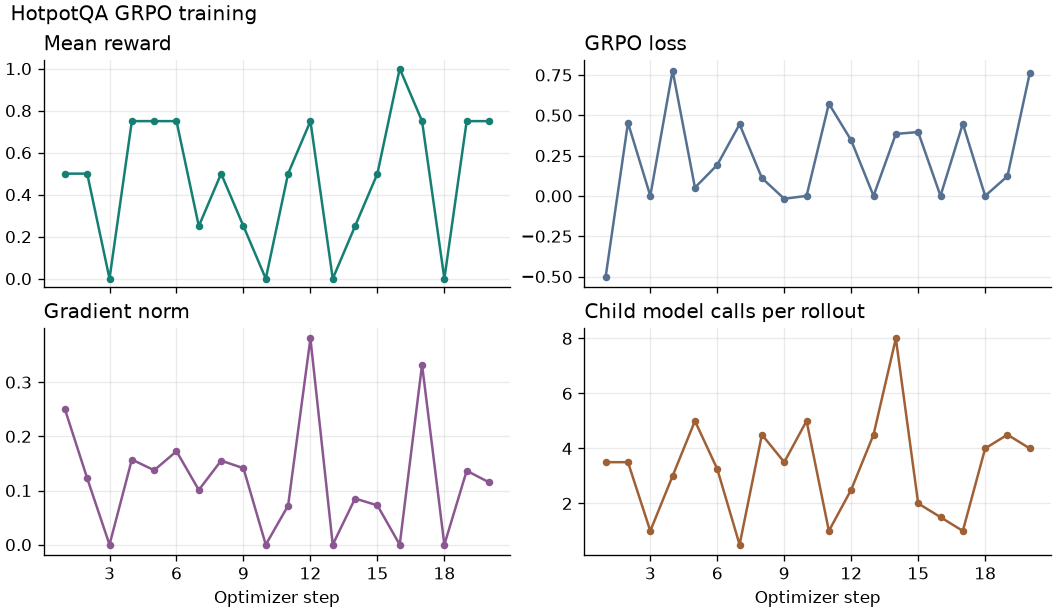

In [ ]:
from matplotlib import pyplot as plt
from matplotlib.ticker import MaxNLocator


history = json.loads((GRPO_DIR / "trainer-history.json").read_text())
metrics = (
    ("reward", "Mean reward", "#147F72"),
    ("loss", "GRPO loss", "#557090"),
    ("grad_norm", "Gradient norm", "#8B5791"),
    ("mean_child_calls", "Child model calls per rollout", "#A06035"),
)
fig, axes = plt.subplots(2, 2, figsize=(8.8, 5.1), sharex=True, layout="constrained")
for ax, (key, label, color) in zip(axes.flat, metrics, strict=True):
    points = [(row["step"], row[key]) for row in history if key in row]
    if points:
        steps, values = zip(*points, strict=True)
        ax.plot(steps, values, marker="o", markersize=3.5, linewidth=1.5, color=color)
    ax.set_title(label, loc="left")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].set_ylim(-0.04, 1.04)
for ax in axes[-1]:
    ax.set_xlabel("Optimizer step")
fig.suptitle("HotpotQA GRPO training", x=0.01, ha="left")
plt.show()

### Read a sampled trajectory

This example shows the root's first turn, a child reply when available, and the scored submission. The JSONL files keep the full conversations.

In [11]:
with Path(training["rollout_trace"]).open(encoding="utf-8") as log:
    traces = [json.loads(line) for line in log]

sample = next((trace for trace in traces if trace["reward"] and trace["child_turns"]), traces[0])
print(sample["question"])
print("\nRoot's first reply:\n", sample["parent_turns"][0]["response"], sep="")
if sample["child_turns"]:
    child_reply = next((turn["response"] for turn in reversed(sample["child_turns"]) if "response" in turn), "")
    print("\nA child reply:\n", child_reply, sep="")
print(f"\nSubmitted: {sample['submitted_answer']!r}")
print(f"Expected: {sample['expected_answer']!r}")
print(f"Reward: {sample['reward']:.0f}")

What nominations has the author of the Eugene Trilogy received more of (combined) than any other writer?

Root's first reply:
```repl
import json
documents = json.loads(context)
print("Article titles available:", list(documents.keys()))
```

A child reply:
```repl
FINAL("The article states Neil Simon has received more combined Oscar and Tony nominations than any other writer, but does not specify the exact number.")
```

Submitted: 'Oscar and Tony nominations'
Expected: 'Oscar and Tony nominations'
Reward: 1


## 5. Compare on held-out questions

Evaluate base Qwen3.5-4B and the SFT + GRPO root on the same validation questions selected by the run mode. Both use the same REPL, prompt, child policy, and greedy decoding. This small comparison measures the combined effect of SFT and GRPO. The training summary above shows whether GRPO updated the adapter.

In [12]:
def evaluate(name, policy, questions, log, completed):
    results = []
    policy.eval()
    with torch.no_grad():
        for row in questions:
            if row["id"] in completed:
                results.append(completed[row["id"]])
                continue
            rollout, trace = run_hotpot_rollout(row, policy, temperature=None)
            answer = rollout["submitted_answer"]
            record = {
                "root": name,
                "question_id": row["id"],
                "question": row["question"],
                "expected": row["answer"],
                "answer": answer,
                "correct": bool(exact_match_reward([row["answer"]], [answer])[0]),
                "non_empty_submission": bool((answer or "").strip()),
                "recursive_child": any(
                    turn["messages"][0]["role"] == "system" and not turn.get("skipped", False)
                    for turn in trace["child_turns"]
                ),
                **trace,
            }
            log.write(json.dumps(record, ensure_ascii=False) + "\n")
            log.flush()
            results.append(record)
    return results


def compare_checkpoints():
    questions = load_questions("validation", HELDOUT_IDS, HELDOUT_QUESTIONS)
    write_json(GRPO_DIR / "validation-question-ids.json", [row["id"] for row in questions])
    trace_file = GRPO_DIR / f"heldout-{HELDOUT_QUESTIONS}-traces.jsonl"
    completed = {"base": {}, "grpo": {}}
    if trace_file.is_file():
        with trace_file.open(encoding="utf-8") as previous:
            for line in previous:
                result = json.loads(line)
                completed[result["root"]][result["question_id"]] = result
    with trace_file.open("a", encoding="utf-8") as log:
        # The base root and its children share the same frozen weights.
        base = evaluate("base", frozen_child(), questions, log, completed["base"])
        frozen_child.cache_clear()
        gc.collect()
        torch.cuda.empty_cache()
        trained = PeftModel.from_pretrained(load_model(ROOT_MODEL, ROOT_REVISION), str(GRPO_DIR / "adapter"))
        grpo = evaluate("grpo", trained, questions, log, completed["grpo"])
    assert [row["question_id"] for row in base] == [row["question_id"] for row in grpo]
    assert all(
        x["parent_turns"][0]["messages"] == y["parent_turns"][0]["messages"] for x, y in zip(base, grpo, strict=True)
    )
    metrics = {
        name: {key: sum(row[key] for row in results) for key in ("correct", "non_empty_submission", "recursive_child")}
        for name, results in (("base", base), ("grpo", grpo))
    }
    gains = sum(y["correct"] and not x["correct"] for x, y in zip(base, grpo, strict=True))
    regressions = sum(x["correct"] and not y["correct"] for x, y in zip(base, grpo, strict=True))
    summary = {"questions": len(questions), **metrics, "gains": gains, "regressions": regressions}
    trackio.init(project=PROJECT, name=f"{GRPO_DIR.name}-heldout", embed=False)
    try:
        trackio.log(
            {
                f"{name}/{key}": value / len(questions)
                for name, values in metrics.items()
                for key, value in values.items()
            },
            step=len(questions),
        )
    finally:
        trackio.finish()
    write_json(GRPO_DIR / "heldout-results.json", summary)
    return summary

### Run the held-out comparison

Run this cell after training to evaluate the base and trained roots on the selected held-out questions. It loads the adapter from the run directory and plots exact matches, answers submitted, and questions that used a child REPL.

In [ ]:
from matplotlib import pyplot as plt
from matplotlib.ticker import MaxNLocator


heldout_path = GRPO_DIR / "heldout-results.json"
if heldout_path.is_file() and json.loads(heldout_path.read_text())["questions"] == HELDOUT_QUESTIONS:
    comparison = json.loads(heldout_path.read_text())
else:
    comparison = compare_checkpoints()

n = comparison["questions"]
metrics = (
    ("correct", "Exact match"),
    ("non_empty_submission", "Submitted an answer"),
    ("recursive_child", "Used a child REPL"),
)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for model, label, color, offset in (
    ("base", "Base Qwen3.5-4B", "#557090", -0.16),
    ("grpo", "SFT + GRPO", "#147F72", 0.16),
):
    counts = [comparison[model][key] for key, _ in metrics]
    bars = ax.barh([i + offset for i in range(len(metrics))], counts, height=0.26, color=color, label=label)
    ax.bar_label(bars, labels=[f"{count}/{n}" for count in counts], padding=5)

ax.set_yticks(range(len(metrics)), [label for _, label in metrics])
ax.invert_yaxis()
ax.set(xlim=(0, n * 1.15), xlabel="Questions", title=f"Held-out comparison on {n} paired questions")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
plt.show()

base 5a83a532554299334474606f: correct=False, child=False
base 5a88dcf9554299206df2b383: correct=True, child=True
base 5ac2bbd0554299218029db09: correct=False, child=False
base 5a7ddc5a5542995f4f4022da: correct=True, child=False
base 5a7a1cd85542990783324e65: correct=False, child=False
base 5ae4c49a5542995dadf24400: correct=False, child=False
base 5abd2eab5542992ac4f38210: correct=True, child=False
base 5a7b46e55542995eb53be8e5: correct=False, child=True
base 5a8eea4a5542990e94052bb7: correct=True, child=False
base 5ab9374b554299131ca422c6: correct=False, child=False
base 5a8b57f25542995d1e6f1371: correct=True, child=True
base 5a8c7595554299585d9e36b6: correct=False, child=False
base 5a85ea095542994775f606a8: correct=True, child=True
base 5adbf0a255429947ff17385a: correct=True, child=False
base 5a8e3ea95542995a26add48d: correct=False, child=False
base 5abd94525542992ac4f382d2: correct=True, child=False
base 5a85b2d95542997b5ce40028: correct=True, child=False
base 5a87ab905542996e4f3088

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


grpo 5a83a532554299334474606f: correct=False, child=True
grpo 5a88dcf9554299206df2b383: correct=True, child=True
grpo 5ac2bbd0554299218029db09: correct=True, child=True
grpo 5a7ddc5a5542995f4f4022da: correct=True, child=True
grpo 5a7a1cd85542990783324e65: correct=True, child=True
grpo 5ae4c49a5542995dadf24400: correct=False, child=True
grpo 5abd2eab5542992ac4f38210: correct=True, child=True
grpo 5a7b46e55542995eb53be8e5: correct=True, child=True
grpo 5a8eea4a5542990e94052bb7: correct=True, child=True
grpo 5ab9374b554299131ca422c6: correct=False, child=True


### Recovered comparison from this run

The saved output contains 20 base results and 10 GRPO results. Run this cell on CPU to plot the 10 questions with saved scores for both models. It uses the recorded scores and does not load either model.

In [ ]:
from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator


# Counts from the ten question IDs shared by both models in the saved output.
questions = 10
metrics = ("Exact match", "Used a child REPL")
fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
for label, counts, color, offset in (
    ("Base Qwen3.5-4B", (4, 2), "#557090", -0.16),
    ("SFT + GRPO", (7, 10), "#147F72", 0.16),
):
    bars = ax.barh([i + offset for i in range(len(metrics))], counts, height=0.26, color=color, label=label)
    ax.bar_label(bars, labels=[f"{count}/{questions}" for count in counts], padding=5)

ax.set_yticks(range(len(metrics)), metrics)
ax.invert_yaxis()
ax.set(xlim=(0, 11), xlabel="Questions", title="HotpotQA held-out comparison on 10 paired questions")
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.show()

### What the REPL evaluation showed

Both roots ran in the same OpenEnv Python REPL with frozen child models. On the **10 paired HotpotQA questions**, the root trained with SFT and GRPO got **7 exact matches**, up from **4** for base Qwen3.5-4B. The trained root delegated to a child REPL on **10 of 10** questions, up from **2 of 10** for the base model. GRPO rewarded correct final answers, so delegation was a behavior the trained root used along the way. To measure GRPO’s contribution separately, we would need to evaluate the SFT checkpoint on the same questions.